# Task 
 1. Analyse tweets and yahoo finance data
 2. Find relationship between close price and tweets.
 3. Forcasting  for the close price for day 1, 3 and 7th.
 4. Time series and LSTM will be used for close price forcasting.
 5. Final Analysis to be made and choices justified.
 

# TABLE OF CONTENTS

1. Understand and clean tweet data.
2. Understand and clean 5 different companies   from yahoo finance data.
3. Merge data
4. Data visualisation 
5. Encoding 
6. Forcasting using LSTM
7. Forcasting using time series 
8. Fine tuning 
9. Results analysis



In [645]:
# load libraries
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense, Input, Dropout
import seaborn as sns
from tensorflow.keras.callbacks import EarlyStopping
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer



# 1.  Stocktweet 


In [646]:
# load data frame
stocktweet = pd.read_csv("stocktweet.csv")
stocktweet

,id,date,ticker,tweet
0,100001,01/01/2020,AMZN,$AMZN Dow futures up by 100 points already 🥳
1,100002,01/01/2020,TSLA,$TSLA Daddy's drinkin' eArly tonight! Here's t...
2,100003,01/01/2020,AAPL,$AAPL We’ll been riding since last December fr...
3,100004,01/01/2020,TSLA,"$TSLA happy new year, 2020, everyone🍷🎉🙏"
4,100005,01/01/2020,TSLA,"$TSLA haha just a collection of greats...""Mars..."
...,...,...,...,...
9995,109996,31/12/2020,ABNB,"$ABNB “sugar daddy puts.” Don’t mind me, I’m j..."
9996,109997,31/12/2020,TSLA,$TSLA \nGood news... now bears can get help wh...
9997,109998,31/12/2020,BABA,$BABA Who else is glad they sold in 240s yeste...
9998,109999,31/12/2020,CCL,$CCL $23 calls for .79 you know what to do 🥳


In [647]:
# check for data type, null values and number of rows and columns.
stocktweet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      10000 non-null  int64 
 1   date    10000 non-null  object
 2   ticker  10000 non-null  object
 3   tweet   10000 non-null  object
dtypes: int64(1), object(3)
memory usage: 312.6+ KB


In [648]:
# check for duplicates
duplicates = stocktweet[stocktweet.duplicated()]
print(duplicates)


Empty DataFrame
Columns: [id, date, ticker, tweet]
Index: []


# Findings 
1. Date is in wrong data type 
2. There are columns and tickers i will not need for my task.
3. NO null values and duplicates.
4. Column names start with small letters, since this is proffessional writting it has to be in capila letters.
5. Tweet column needs to be cleaned and converted. 

In [649]:
# drop columns not needed
stocktweet = stocktweet.drop(columns=["id"], errors="ignore")
stocktweet

,date,ticker,tweet
0,01/01/2020,AMZN,$AMZN Dow futures up by 100 points already 🥳
1,01/01/2020,TSLA,$TSLA Daddy's drinkin' eArly tonight! Here's t...
2,01/01/2020,AAPL,$AAPL We’ll been riding since last December fr...
3,01/01/2020,TSLA,"$TSLA happy new year, 2020, everyone🍷🎉🙏"
4,01/01/2020,TSLA,"$TSLA haha just a collection of greats...""Mars..."
...,...,...,...
9995,31/12/2020,ABNB,"$ABNB “sugar daddy puts.” Don’t mind me, I’m j..."
9996,31/12/2020,TSLA,$TSLA \nGood news... now bears can get help wh...
9997,31/12/2020,BABA,$BABA Who else is glad they sold in 240s yeste...
9998,31/12/2020,CCL,$CCL $23 calls for .79 you know what to do 🥳


In [650]:
# Keep only the desired companies in ticker
stocktweet_f = stocktweet[stocktweet["ticker"].isin(["TSLA", "AAPL", "BA", "DIS", "AMZN"])]

# Save the filtered data
stocktweet_f.to_csv("stocktweetfiltered_data.csv", index=False)

print(stocktweet_f)  # Display filtered data

            date ticker                                              tweet
0     01/01/2020   AMZN       $AMZN Dow futures up by 100 points already 🥳
1     01/01/2020   TSLA  $TSLA Daddy's drinkin' eArly tonight! Here's t...
2     01/01/2020   AAPL  $AAPL We’ll been riding since last December fr...
3     01/01/2020   TSLA            $TSLA happy new year, 2020, everyone🍷🎉🙏
4     01/01/2020   TSLA  $TSLA haha just a collection of greats..."Mars...
...          ...    ...                                                ...
9983  23/12/2020   TSLA  $TSLA strong strong strong!!!! Let’s push it $...
9987  27/12/2020   AAPL               $AAPL let’s have a great week !  🚀🚀🚀
9994  30/12/2020   TSLA                       $TSLA all I see the green 🕯️
9996  31/12/2020   TSLA  $TSLA \nGood news... now bears can get help wh...
9999  31/12/2020   TSLA  $TSLA  🔥 closed out 15k in profit!Happy New Ye...

[7820 rows x 3 columns]


In [651]:
# change data type from object to date time.

stocktweet_f= stocktweet_f.copy()
stocktweet_f["date"] = pd.to_datetime(stocktweet_f["date"], format="%d/%m/%Y")


In [652]:
#Check if date has been changed to the right datatype (datetime) 
stocktweet_f.dtypes

date      datetime64[ns]
ticker            object
tweet             object
dtype: object

In [653]:
# Rename columns 
stocktweet_f = stocktweet_f.rename(columns={"date": "Date",
                        "ticker" : "Ticker",
                        "tweet": "Tweet"})
stocktweet_f

,Date,Ticker,Tweet
0,2020-01-01,AMZN,$AMZN Dow futures up by 100 points already 🥳
1,2020-01-01,TSLA,$TSLA Daddy's drinkin' eArly tonight! Here's t...
2,2020-01-01,AAPL,$AAPL We’ll been riding since last December fr...
3,2020-01-01,TSLA,"$TSLA happy new year, 2020, everyone🍷🎉🙏"
4,2020-01-01,TSLA,"$TSLA haha just a collection of greats...""Mars..."
...,...,...,...
9983,2020-12-23,TSLA,$TSLA strong strong strong!!!! Let’s push it $...
9987,2020-12-27,AAPL,$AAPL let’s have a great week ! 🚀🚀🚀
9994,2020-12-30,TSLA,$TSLA all I see the green 🕯️
9996,2020-12-31,TSLA,$TSLA \nGood news... now bears can get help wh...


In [654]:
df = stocktweet_f

In [655]:
df

,Date,Ticker,Tweet
0,2020-01-01,AMZN,$AMZN Dow futures up by 100 points already 🥳
1,2020-01-01,TSLA,$TSLA Daddy's drinkin' eArly tonight! Here's t...
2,2020-01-01,AAPL,$AAPL We’ll been riding since last December fr...
3,2020-01-01,TSLA,"$TSLA happy new year, 2020, everyone🍷🎉🙏"
4,2020-01-01,TSLA,"$TSLA haha just a collection of greats...""Mars..."
...,...,...,...
9983,2020-12-23,TSLA,$TSLA strong strong strong!!!! Let’s push it $...
9987,2020-12-27,AAPL,$AAPL let’s have a great week ! 🚀🚀🚀
9994,2020-12-30,TSLA,$TSLA all I see the green 🕯️
9996,2020-12-31,TSLA,$TSLA \nGood news... now bears can get help wh...


In [656]:
# save changes to csv file 
df.to_csv("df.csv")

# CLEAN TWEETS

In [657]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\elias\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\elias\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\elias\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [658]:
# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()


In [659]:
# Initialize the VADER Sentiment Analyzer
sia = SentimentIntensityAnalyzer()


In [660]:
# clean text 
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Remove mentions and hashtags
    text = re.sub(r'@\w+|#\w+', '', text)
    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Tokenize text
    words = text.split()
    # Remove stop words
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words]
    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    # Join words back into a single string
    return ' '.join(words)

#  cleaning the "tweets" column
df["Cleaned_tweets"] = df["Tweet"].apply(clean_text)

# Display cleaned DataFrame
print(df)

           Date Ticker                                              Tweet  \
0    2020-01-01   AMZN       $AMZN Dow futures up by 100 points already 🥳   
1    2020-01-01   TSLA  $TSLA Daddy's drinkin' eArly tonight! Here's t...   
2    2020-01-01   AAPL  $AAPL We’ll been riding since last December fr...   
3    2020-01-01   TSLA            $TSLA happy new year, 2020, everyone🍷🎉🙏   
4    2020-01-01   TSLA  $TSLA haha just a collection of greats..."Mars...   
...         ...    ...                                                ...   
9983 2020-12-23   TSLA  $TSLA strong strong strong!!!! Let’s push it $...   
9987 2020-12-27   AAPL               $AAPL let’s have a great week !  🚀🚀🚀   
9994 2020-12-30   TSLA                       $TSLA all I see the green 🕯️   
9996 2020-12-31   TSLA  $TSLA \nGood news... now bears can get help wh...   
9999 2020-12-31   TSLA  $TSLA  🔥 closed out 15k in profit!Happy New Ye...   

                                         Cleaned_tweets  
0                

In [661]:
# Apply VADER sentiment analysis
def analyze_sentiment(text):
    sentiment = sia.polarity_scores(text)
    return sentiment

# Create new columns for sentiment scores
df['sentiment'] = df['Cleaned_tweets'].apply(analyze_sentiment)
df['compound'] = df['sentiment'].apply(lambda x: x['compound'])
df['sentiment_label'] = df['compound'].apply(
    lambda x: 'positive' if x > 0.05 else 'negative' if x < -0.05 else 'neutral'
)

# Display the DataFrame with sentiment analysis results
print(df)

           Date Ticker                                              Tweet  \
0    2020-01-01   AMZN       $AMZN Dow futures up by 100 points already 🥳   
1    2020-01-01   TSLA  $TSLA Daddy's drinkin' eArly tonight! Here's t...   
2    2020-01-01   AAPL  $AAPL We’ll been riding since last December fr...   
3    2020-01-01   TSLA            $TSLA happy new year, 2020, everyone🍷🎉🙏   
4    2020-01-01   TSLA  $TSLA haha just a collection of greats..."Mars...   
...         ...    ...                                                ...   
9983 2020-12-23   TSLA  $TSLA strong strong strong!!!! Let’s push it $...   
9987 2020-12-27   AAPL               $AAPL let’s have a great week !  🚀🚀🚀   
9994 2020-12-30   TSLA                       $TSLA all I see the green 🕯️   
9996 2020-12-31   TSLA  $TSLA \nGood news... now bears can get help wh...   
9999 2020-12-31   TSLA  $TSLA  🔥 closed out 15k in profit!Happy New Ye...   

                                         Cleaned_tweets  \
0               

In [662]:
df.drop(columns=["Tweet", "Cleaned_tweets", "sentiment"], inplace=True)

df

,Date,Ticker,compound,sentiment_label
0,2020-01-01,AMZN,0.0000,neutral
1,2020-01-01,TSLA,0.0000,neutral
2,2020-01-01,AAPL,0.2732,positive
3,2020-01-01,TSLA,0.5719,positive
4,2020-01-01,TSLA,0.7717,positive
...,...,...,...,...
9983,2020-12-23,TSLA,0.9287,positive
9987,2020-12-27,AAPL,0.6249,positive
9994,2020-12-30,TSLA,0.0000,neutral
9996,2020-12-31,TSLA,0.6808,positive


#  Company Dataset

# TSLA DATASET

In [663]:
# load dataset
TSLA = pd.read_csv("TSLA.CSV")
TSLA

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-12-31,27.000000,28.086000,26.805332,27.888666,27.888666,154285500
1,2020-01-02,28.299999,28.713333,28.114000,28.684000,28.684000,142981500
2,2020-01-03,29.366667,30.266666,29.128000,29.534000,29.534000,266677500
3,2020-01-06,29.364668,30.104000,29.333332,30.102667,30.102667,151995000
4,2020-01-07,30.760000,31.441999,30.224001,31.270666,31.270666,268231500
...,...,...,...,...,...,...,...
249,2020-12-24,214.330002,222.029999,213.666672,220.589996,220.589996,68596800
250,2020-12-28,224.836670,227.133331,220.266663,221.229996,221.229996,96835800
251,2020-12-29,220.333328,223.300003,218.333328,221.996674,221.996674,68732400
252,2020-12-30,224.000000,232.199997,222.786667,231.593338,231.593338,128538000


In [664]:
# check for null values, see if  data tpes are correctly allocated, number of rows and columns.
TSLA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       254 non-null    object 
 1   Open       254 non-null    float64
 2   High       254 non-null    float64
 3   Low        254 non-null    float64
 4   Close      254 non-null    float64
 5   Adj Close  254 non-null    float64
 6   Volume     254 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 14.0+ KB


In [665]:
# check for duplicates. 
duplicates = TSLA[TSLA.duplicated()]
print(duplicates)


Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj Close, Volume]
Index: []


# Findings 
1. Date is in wrong data format.
2. There are columns i will not need for my task.
3. NO null values and duplicates.


In [666]:
# Date to day time data type
TSLA["Date"] = pd.to_datetime(TSLA["Date"])  


In [667]:
# Generate business days only between Jan 3, 2020 and Dec 31, 2020
business_days = pd.date_range(start='2020-01-03', end='2020-12-31', freq='B')


In [668]:
# Filter for business days in TSLA dataset
TSLA = TSLA[TSLA['Date'].isin(business_days)]

In [669]:
# drop unwanted columns
TSLA = TSLA.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])

TSLA


,Date,Close
2,2020-01-03,29.534000
3,2020-01-06,30.102667
4,2020-01-07,31.270666
5,2020-01-08,32.809334
6,2020-01-09,32.089333
...,...,...
249,2020-12-24,220.589996
250,2020-12-28,221.229996
251,2020-12-29,221.996674
252,2020-12-30,231.593338


# AAPL DATASET

In [670]:
#load dataset
AAPL = pd.read_csv("AAPL.CSV")
AAPL

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-12-31,72.482498,73.419998,72.379997,73.412498,71.520821,100805600
1,2020-01-02,74.059998,75.150002,73.797501,75.087502,73.152649,135480400
2,2020-01-03,74.287498,75.144997,74.125000,74.357498,72.441460,146322800
3,2020-01-06,73.447502,74.989998,73.187500,74.949997,73.018677,118387200
4,2020-01-07,74.959999,75.224998,74.370003,74.597504,72.675278,108872000
...,...,...,...,...,...,...,...
249,2020-12-24,131.320007,133.460007,131.100006,131.970001,129.679718,54930100
250,2020-12-28,133.990005,137.339996,133.509995,136.690002,134.317825,124486200
251,2020-12-29,138.050003,138.789993,134.339996,134.869995,132.529404,121047300
252,2020-12-30,135.580002,135.990005,133.399994,133.720001,131.399368,96452100


In [671]:
AAPL.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       254 non-null    object 
 1   Open       254 non-null    float64
 2   High       254 non-null    float64
 3   Low        254 non-null    float64
 4   Close      254 non-null    float64
 5   Adj Close  254 non-null    float64
 6   Volume     254 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 14.0+ KB


In [672]:
# check for duplicates. 
duplicates = AAPL[AAPL.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj Close, Volume]
Index: []


# Findings 
1. Date is in wrong data format.
2. There are columns i will not need for my task.
3. NO null values and duplicates.


In [673]:
# Date to day time data type
AAPL["Date"] = pd.to_datetime(AAPL["Date"])  


In [674]:
# Generate business days only between Jan 3, 2020 and Dec 31, 2020
business_days = pd.date_range(start='2020-01-03', end='2020-12-31', freq='B')


In [675]:
# Filter for business days in AAPL dataset
AAPL = AAPL[AAPL['Date'].isin(business_days)]

In [676]:
# drop unwanted columns
AAPL = AAPL.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])
AAPL

,Date,Close
2,2020-01-03,74.357498
3,2020-01-06,74.949997
4,2020-01-07,74.597504
5,2020-01-08,75.797501
6,2020-01-09,77.407501
...,...,...
249,2020-12-24,131.970001
250,2020-12-28,136.690002
251,2020-12-29,134.869995
252,2020-12-30,133.720001


# BA DATASET

In [677]:
#load dataset
BA = pd.read_csv("BA.CSV")
BA

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-12-31,325.410004,326.570007,323.320007,325.760010,323.833313,4958800
1,2020-01-02,328.549988,333.350006,327.700012,333.320007,331.348572,4544400
2,2020-01-03,330.630005,334.890015,330.299988,332.760010,330.791901,3875900
3,2020-01-06,329.299988,334.859985,327.880005,333.739990,331.766083,5355000
4,2020-01-07,334.260010,344.190002,330.709991,337.279999,335.285156,9898600
...,...,...,...,...,...,...,...
249,2020-12-24,219.619995,219.880005,216.050003,217.149994,217.149994,6398500
250,2020-12-28,218.190002,219.199997,215.160004,216.089996,216.089996,9090600
251,2020-12-29,218.300003,221.679993,215.399994,216.250000,216.250000,14593800
252,2020-12-30,216.360001,218.550003,214.369995,216.669998,216.669998,10812600


In [678]:
BA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       254 non-null    object 
 1   Open       254 non-null    float64
 2   High       254 non-null    float64
 3   Low        254 non-null    float64
 4   Close      254 non-null    float64
 5   Adj Close  254 non-null    float64
 6   Volume     254 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 14.0+ KB


In [679]:
# check for duplicates. 
duplicates = BA[BA.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj Close, Volume]
Index: []


# Findings 
1. Date is in wrong data format.
2. There are columns i will not need for my task.
3. NO null values and duplicates.


In [680]:
# Date to day time data type
BA["Date"] = pd.to_datetime(BA["Date"])  


In [681]:
# Generate business days only between Jan 3, 2020 and Dec 31, 2020
business_days = pd.date_range(start='2020-01-03', end='2020-12-31', freq='B')


In [682]:
# Filter for business days in BA dataset
BA = BA[BA['Date'].isin(business_days)]

In [683]:
# drop unwanted columns
BA = BA.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])

BA

,Date,Close
2,2020-01-03,332.760010
3,2020-01-06,333.739990
4,2020-01-07,337.279999
5,2020-01-08,331.369995
6,2020-01-09,336.339996
...,...,...
249,2020-12-24,217.149994
250,2020-12-28,216.089996
251,2020-12-29,216.250000
252,2020-12-30,216.669998


# DIS DATASET

In [684]:
#load dataset
DIS = pd.read_csv("DIS.CSV")
DIS

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-12-31,143.669998,144.770004,143.259995,144.630005,144.160172,5662900
1,2020-01-02,145.289993,148.199997,145.100006,148.199997,147.718567,9502100
2,2020-01-03,146.399994,147.899994,146.050003,146.500000,146.024094,7320200
3,2020-01-06,145.539993,146.029999,144.309998,145.649994,145.176849,8262500
4,2020-01-07,145.990005,146.869995,145.419998,145.699997,145.226685,6906500
...,...,...,...,...,...,...,...
249,2020-12-24,173.990005,174.580002,172.380005,173.729996,173.165634,2721000
250,2020-12-28,175.750000,179.919998,175.050003,178.860001,178.278976,13145400
251,2020-12-29,180.009995,180.199997,176.220001,177.300003,176.724045,6875400
252,2020-12-30,178.500000,183.399994,178.369995,181.169998,180.581467,11680400


In [685]:
DIS.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       254 non-null    object 
 1   Open       254 non-null    float64
 2   High       254 non-null    float64
 3   Low        254 non-null    float64
 4   Close      254 non-null    float64
 5   Adj Close  254 non-null    float64
 6   Volume     254 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 14.0+ KB


In [686]:
# check for duplicates. 
duplicates = DIS[DIS.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj Close, Volume]
Index: []


# Findings 
1. Date is in wrong data format.
2. There are columns i will not need for my task.
3. NO null values and duplicates.


In [687]:
# Date to day time data type
DIS["Date"] = pd.to_datetime(DIS["Date"])  


In [688]:
# Generate business days only between Jan 3, 2020 and Dec 31, 2020
business_days = pd.date_range(start='2020-01-03', end='2020-12-31', freq='B')


In [689]:
# Filter for business days in DIS dataset
DIS = DIS[DIS['Date'].isin(business_days)]

In [690]:
# drop unwanted columns
DIS = DIS.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])
DIS

,Date,Close
2,2020-01-03,146.500000
3,2020-01-06,145.649994
4,2020-01-07,145.699997
5,2020-01-08,145.399994
6,2020-01-09,144.830002
...,...,...
249,2020-12-24,173.729996
250,2020-12-28,178.860001
251,2020-12-29,177.300003
252,2020-12-30,181.169998


# AMZN DATASET

In [691]:
#load dataset
AMZN = pd.read_csv("AMZN.CSV")
AMZN

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-12-31,92.099998,92.663002,91.611504,92.391998,92.391998,50130000
1,2020-01-02,93.750000,94.900497,93.207497,94.900497,94.900497,80580000
2,2020-01-03,93.224998,94.309998,93.224998,93.748497,93.748497,75288000
3,2020-01-06,93.000000,95.184502,93.000000,95.143997,95.143997,81236000
4,2020-01-07,95.224998,95.694504,94.601997,95.343002,95.343002,80898000
...,...,...,...,...,...,...,...
249,2020-12-24,159.695007,160.100006,158.449997,158.634506,158.634506,29038000
250,2020-12-28,159.699997,165.199997,158.634506,164.197998,164.197998,113736000
251,2020-12-29,165.496994,167.532501,164.061005,166.100006,166.100006,97458000
252,2020-12-30,167.050003,167.104996,164.123505,164.292496,164.292496,64186000


In [692]:
AMZN.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       254 non-null    object 
 1   Open       254 non-null    float64
 2   High       254 non-null    float64
 3   Low        254 non-null    float64
 4   Close      254 non-null    float64
 5   Adj Close  254 non-null    float64
 6   Volume     254 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 14.0+ KB


In [693]:
# check for duplicates. 
duplicates = AMZN[AMZN.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj Close, Volume]
Index: []


# Findings 
1. Date is in wrong data format.
2. There are columns i will not need for my task.
3. NO null values and duplicates.


In [694]:
# Date to day time data type
AMZN["Date"] = pd.to_datetime(AMZN["Date"])  


In [695]:
# Generate business days only between Jan 3, 2020 and Dec 31, 2020
business_days = pd.date_range(start='2020-01-03', end='2020-12-31', freq='B')


In [696]:
AMZN = AMZN[AMZN['Date'].isin(business_days)]

In [697]:
# drop un wanted columns
AMZN = AMZN.drop(columns=['Open', 'High', 'Low', 'Adj Close', 'Volume'])
AMZN

,Date,Close
2,2020-01-03,93.748497
3,2020-01-06,95.143997
4,2020-01-07,95.343002
5,2020-01-08,94.598503
6,2020-01-09,95.052498
...,...,...
249,2020-12-24,158.634506
250,2020-12-28,164.197998
251,2020-12-29,166.100006
252,2020-12-30,164.292496


# Merdge data

# Concat  5 choosen company datasets

In [698]:

# CONCAT COMPANY DATASET
hh = pd.concat([TSLA, AAPL, DIS, BA, AMZN], ignore_index=True)


In [699]:
hh

,Date,Close
0,2020-01-03,29.534000
1,2020-01-06,30.102667
2,2020-01-07,31.270666
3,2020-01-08,32.809334
4,2020-01-09,32.089333
...,...,...
1255,2020-12-24,158.634506
1256,2020-12-28,164.197998
1257,2020-12-29,166.100006
1258,2020-12-30,164.292496


In [700]:
# Convert 'Date' columns to datetime in both DataFrames
hh['Date'] = pd.to_datetime(hh['Date'])
df['Date'] = pd.to_datetime(df['Date'])


In [701]:
# merge dataset
finaldataset = pd.merge(hh, df, on="Date", how="left")

In [702]:
# check for null values
finaldataset.isnull().sum()


Date               0
Close              0
Ticker             0
compound           0
sentiment_label    0
dtype: int64

In [703]:
# drop null values
finaldataset.dropna()


,Date,Close,Ticker,compound,sentiment_label
0,2020-01-03,29.534000,AAPL,0.0000,neutral
1,2020-01-03,29.534000,AAPL,0.1027,positive
2,2020-01-03,29.534000,AAPL,-0.0516,negative
3,2020-01-03,29.534000,AAPL,0.0000,neutral
4,2020-01-03,29.534000,TSLA,0.2023,positive
...,...,...,...,...,...
37550,2020-12-31,162.846497,BA,0.0000,neutral
37551,2020-12-31,162.846497,TSLA,0.0000,neutral
37552,2020-12-31,162.846497,TSLA,-0.1027,negative
37553,2020-12-31,162.846497,TSLA,0.6808,positive


In [704]:
finaldataset.to_csv('finaldataset.csv')

# SET INDEX AS DATE TIME 

In [705]:
# select a specific ticker using date as the index because its a time series data
ba_stock = finaldataset[finaldataset["Ticker"] == "BA"][["Date", "Close", "Ticker", "sentiment_label", "compound"]]
ba_stock.set_index('Date', inplace=True)


In [706]:
ba_stock 

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-07,31.270666,BA,negative,-0.3252
2020-01-07,31.270666,BA,positive,0.3182
2020-01-08,32.809334,BA,negative,-0.6908
2020-01-10,31.876667,BA,neutral,0.0000
2020-01-10,31.876667,BA,negative,-0.4404
...,...,...,...,...
2020-12-23,159.263504,BA,positive,0.4215
2020-12-29,166.100006,BA,negative,-0.7506
2020-12-29,166.100006,BA,negative,-0.5574


In [707]:
# save it as csv file to later use it for ML model 
ba_stock.to_csv('ba_stock.csv', index=False)


In [708]:
# select a specific ticker using date as the index because its a time series data
tsla_stock = finaldataset[finaldataset["Ticker"] == "TSLA"][["Date", "Close", "Ticker", "sentiment_label", "compound"]]
tsla_stock.set_index('Date', inplace=True)


In [709]:
tsla_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-03,29.534000,TSLA,positive,0.2023
2020-01-03,29.534000,TSLA,neutral,0.0000
2020-01-03,29.534000,TSLA,negative,-0.0951
2020-01-03,29.534000,TSLA,positive,0.3612
2020-01-03,29.534000,TSLA,negative,-0.4767
...,...,...,...,...
2020-12-31,162.846497,TSLA,positive,0.8316
2020-12-31,162.846497,TSLA,neutral,0.0000
2020-12-31,162.846497,TSLA,negative,-0.1027


In [710]:
tsla_stock.to_csv('tsla_stock.csv', index=False)


In [711]:
# select a specific ticker using date as the index because its a time series data
amzn_stock = finaldataset[finaldataset["Ticker"] == "AMZN"][["Date", "Close", "Ticker", "sentiment_label", "compound"]]
amzn_stock.set_index('Date', inplace=True)


In [712]:
amzn_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-03,29.534000,AMZN,neutral,0.0000
2020-01-06,30.102667,AMZN,positive,0.4404
2020-01-07,31.270666,AMZN,positive,0.7650
2020-01-09,32.089333,AMZN,neutral,0.0000
2020-01-10,31.876667,AMZN,positive,0.0772
...,...,...,...,...
2020-12-29,166.100006,AMZN,neutral,0.0000
2020-12-29,166.100006,AMZN,negative,-0.6369
2020-12-29,166.100006,AMZN,neutral,0.0000


In [713]:
amzn_stock.to_csv('amzn_stock.csv', index=False)


In [714]:
aapl_stock = finaldataset[finaldataset["Ticker"] == "AAPL"][["Date", "Close", "Ticker", "sentiment_label", "compound"]]
aapl_stock.set_index('Date', inplace=True)


In [715]:
aapl_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-03,29.534000,AAPL,neutral,0.0000
2020-01-03,29.534000,AAPL,positive,0.1027
2020-01-03,29.534000,AAPL,negative,-0.0516
2020-01-03,29.534000,AAPL,neutral,0.0000
2020-01-03,29.534000,AAPL,neutral,0.0000
...,...,...,...,...
2020-12-29,166.100006,AAPL,neutral,0.0000
2020-12-30,164.292496,AAPL,neutral,0.0000
2020-12-31,162.846497,AAPL,positive,0.0772


In [716]:
aapl_stock.to_csv('aapl_stock.csv', index=False)


In [717]:
dis_stock = finaldataset[finaldataset["Ticker"] == "DIS"][["Date", "Close", "Ticker", "sentiment_label", "compound"]]
dis_stock.set_index('Date', inplace=True)


In [718]:
dis_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-07,31.270666,DIS,negative,-0.7783
2020-01-08,32.809334,DIS,positive,0.5468
2020-01-08,32.809334,DIS,neutral,0.0000
2020-01-09,32.089333,DIS,positive,0.4939
2020-01-09,32.089333,DIS,neutral,0.0000
...,...,...,...,...
2020-12-30,164.292496,DIS,negative,-0.6597
2020-12-30,164.292496,DIS,neutral,0.0000
2020-12-30,164.292496,DIS,negative,-0.3182


In [719]:
dis_stock.to_csv('dis_stock.csv', index=False)


# Data visualisation

 1. Seaborn and Matplotlib will be used for visualisation.
 2. visualisation for merged stock and tweet will be made. 
 3. Find distribution of the closing price of companies  over the years.
 4. Find correlation of columns using heat map.
 5. Find minimum & maximum and outliers of data using boxplot.
 6. Distribution plot for closing price and average sentiment.
 7. Bar plot for sentiment label distribution.
 8. Sentiment label with company. 


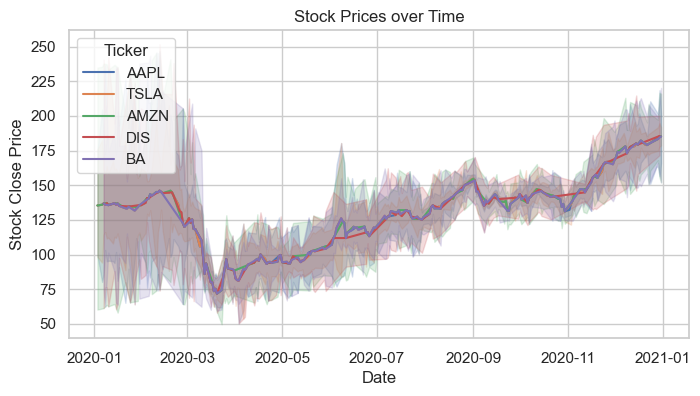

In [809]:
# Visualize the distribution of stock prices
plt.figure(figsize=(8,4))
sns.lineplot(data=finaldataset, x='Date', y='Close', hue='Ticker')
plt.title('Stock Prices over Time')
plt.xlabel('Date')
plt.ylabel('Stock Close Price')
plt.show()

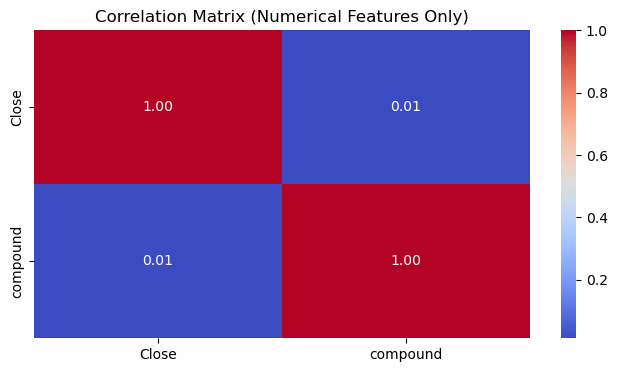

In [396]:
# Find correlation of columns using heat map.

# Select only numeric columns for correlation
numeric_df = finaldataset.select_dtypes(include=['number'])

# Compute correlation matrix
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix (Numerical Features Only)")
plt.show()


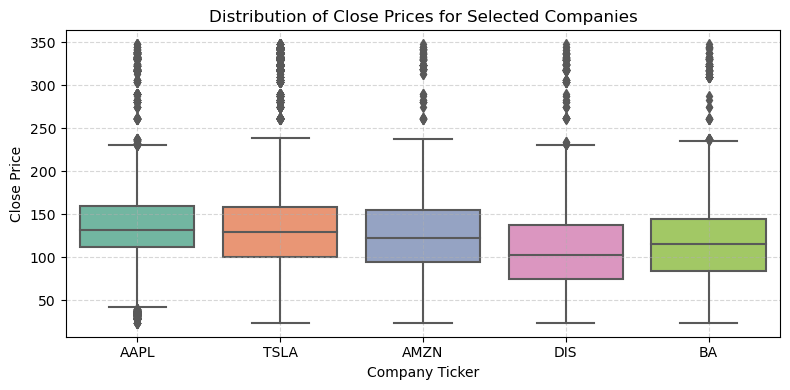

In [397]:
# to find minimum,  maximum and outliers of close price for each company  using boxplot.

plt.figure(figsize=(8, 4))
sns.boxplot(data=finaldataset, x='Ticker', y='Close', palette='Set2')

plt.title('Distribution of Close Prices for Selected Companies')
plt.xlabel('Company Ticker')
plt.ylabel('Close Price')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

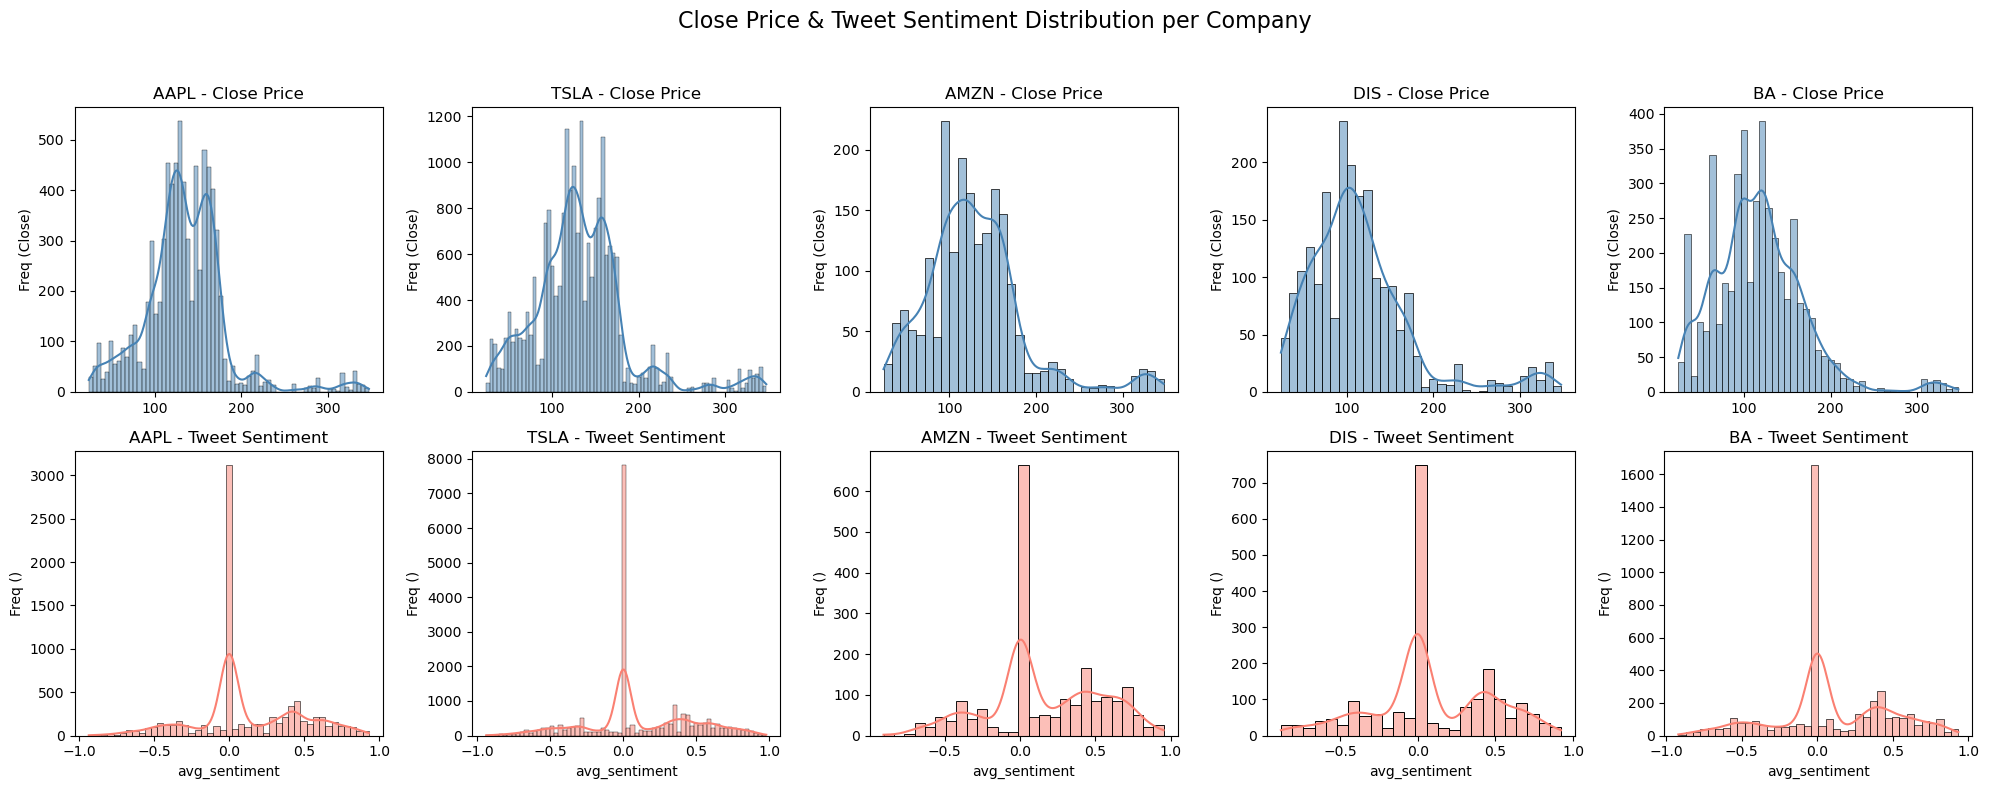

In [362]:
# Distribution plot for closing price and average sentiment 
# Determine number of tickers (companies)
tickers = finaldataset['Ticker'].unique()
n_tickers = len(tickers)

# Set up subplots: 2 rows for Close and Sentiment distributions, and dynamic columns
n_cols = n_tickers  # Number of tickers
n_rows = 2  # 1 row for Close Price, 1 row for Sentiment

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, 8)) 

# If only one row or column, axes won't be 2D.we  will  ensure axes is always 2D for ease of iteration.
if n_cols == 1:
    axes = np.expand_dims(axes, axis=1)
if n_rows == 1:
    axes = np.expand_dims(axes, axis=0)

# Plot distributions
for i, ticker in enumerate(tickers):
    subset = finaldataset[finaldataset['Ticker'] == ticker]
    
    # Close Price Distribution
    sns.histplot(subset['Close'], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{ticker} - Close Price')
    axes[0, i].set_xlabel('')
    
    # Sentiment Distribution
    sns.histplot(subset['compound'], kde=True, ax=axes[1, i], color='salmon')
    axes[1, i].set_title(f'{ticker} - Tweet Sentiment')
    axes[1, i].set_xlabel('avg_sentiment')

# Label axes
for ax in axes[0, :]:
    ax.set_ylabel('Freq (Close)')
for ax in axes[1, :]:
    ax.set_ylabel('Freq ()')

plt.suptitle('Close Price & Tweet Sentiment Distribution per Company', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


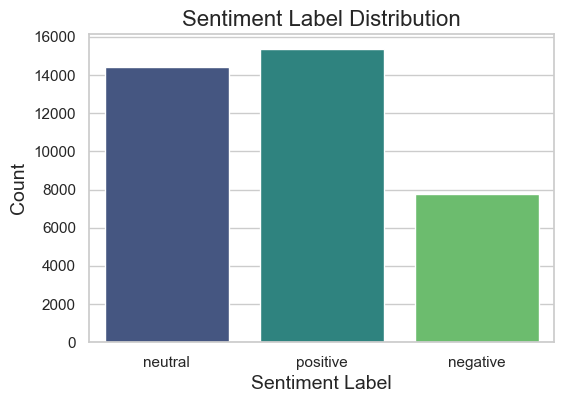

In [808]:
# Create a bar chart for sentiment distribution


# Count the occurrences of each sentiment label in the dataset
plt.figure(figsize=(6, 4))

# Create a count plot for the sentiment labels
sns.countplot(data=finaldataset, x='sentiment_label', palette='viridis')

# Set the title and labels
plt.title('Sentiment Label Distribution', fontsize=16)
plt.xlabel('Sentiment Label', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Display the plot
plt.show()


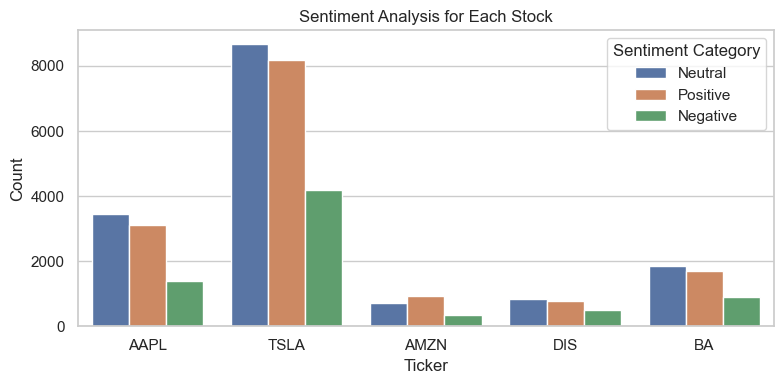

In [807]:
# Categorize sentiment scores based on Vader
def categorize_sentiment(score):
    if score > 0.1:
        return 'Positive'
    elif score < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

# Apply categorization
finaldataset['sentiment_category'] = finaldataset['compound'].apply(categorize_sentiment)

# Set the style of the visualization
sns.set(style="whitegrid")

# Create a bar plot showing the count of each sentiment category for each ticker symbol
plt.figure(figsize=(8, 4))
sns.countplot(x='Ticker', hue='sentiment_category', data=finaldataset)

# Add titles and labels
plt.title('Sentiment Analysis for Each Stock')
plt.xlabel('Ticker')
plt.ylabel('Count')
plt.legend(title='Sentiment Category')
plt.tight_layout()
plt.show()

# LSTM

In [721]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [722]:
tsla_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-03,29.534000,TSLA,positive,0.2023
2020-01-03,29.534000,TSLA,neutral,0.0000
2020-01-03,29.534000,TSLA,negative,-0.0951
2020-01-03,29.534000,TSLA,positive,0.3612
2020-01-03,29.534000,TSLA,negative,-0.4767
...,...,...,...,...
2020-12-31,162.846497,TSLA,positive,0.8316
2020-12-31,162.846497,TSLA,neutral,0.0000
2020-12-31,162.846497,TSLA,negative,-0.1027


In [723]:
# scale
scaler = MinMaxScaler()
tsla_stock['Close_scaled'] = scaler.fit_transform(tsla_stock[['Close']])
tsla_stock['Compound_scaled'] = scaler.fit_transform(tsla_stock[['compound']])


In [724]:
# set for x
x=tsla_stock["Compound_scaled"].values


In [725]:
# set for y
y=tsla_stock["Close_scaled"].values


In [726]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=0)


In [727]:
# Reshape input for LSTM: (samples, timesteps, features)

x_train = x_train.reshape((x_train.shape[0], 1, 1))
x_test = x_test.reshape((x_test.shape[0], 1, 1))


In [773]:
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(x_train.shape[1], 1), return_sequences=True))
model.add(LSTM(50, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')


C:\Users\elias\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [774]:
# Train model
model.fit(x_train, y_train, epochs=25, batch_size=16, validation_data=(x_test, y_test))


Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.0558 - val_loss: 0.0221
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0226 - val_loss: 0.0218
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0220 - val_loss: 0.0218
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0216 - val_loss: 0.0217
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0208 - val_loss: 0.0217
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0206 - val_loss: 0.0217
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0214 - val_loss: 0.0217
Epoch 8/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0210 - val_loss: 0.0218
Epoch 9/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0221 - val_loss: 0.0217
Epoch 10/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0213 - val_loss: 0.0219
Epoch 11/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0225 - val_loss: 0.0217
Epoch 12/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

In [775]:
#  ensure last_seq is 2D: (sequence_length, 1)
last_seq = last_seq.reshape(-1, 1)


In [733]:
# Ensure last_seq is shaped correctly
last_seq = last_seq.reshape(-1, 1)
predictions_scaled = []

for _ in range(7):
    next_pred = model.predict(last_seq.reshape(1, -1, 1), verbose=0)[0][0]
    predictions_scaled.append(next_pred)
    last_seq = np.append(last_seq[1:], [[next_pred]], axis=0)

# Inverse scale
predicted_close = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))

# Print results
print("\n📈 Predicted Close Prices:")
print(f"Day 1 ahead: {predicted_close[0][0]:.2f}")
print(f"Day 3 ahead: {predicted_close[2][0]:.2f}")
print(f"Day 7 ahead: {predicted_close[6][0]:.2f}")



📈 Predicted Close Prices:
Day 1 ahead: -0.31
Day 3 ahead: -0.31
Day 7 ahead: -0.31


In [734]:

from sklearn.metrics import r2_score

# Calculate R² Score
r2 = r2_score(true_values, predicted_close)
print(f"R² Score: {r2:.4f}")


R² Score: -3268.8646


C:\Users\elias\AppData\Local\Temp\ipykernel_61824\2106532007.py:23: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.

C:\Users\elias\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.



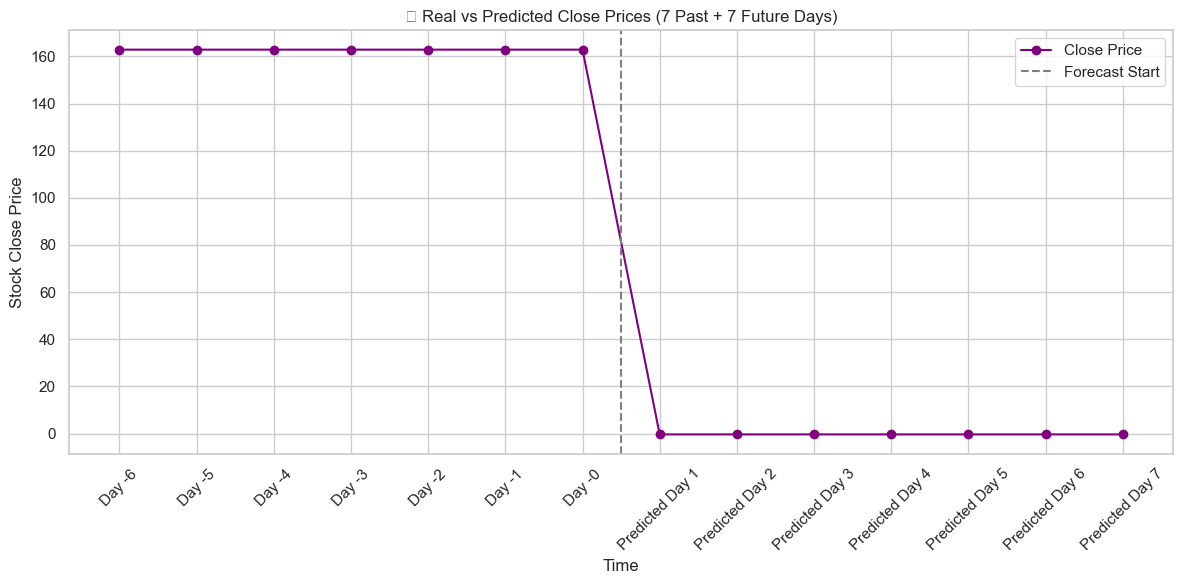

In [644]:
import matplotlib.pyplot as plt
import numpy as np

# Get last 7 real close prices (adjust to 7 or more if you like)
real_previous_7 = tsla_stock['Close'][-7:].values  

# Combine both
full_series = np.concatenate((real_previous_7, predicted_close.flatten()))

# Build matching labels (7 actual + 7 predicted = 14)
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(days, full_series, marker='o', linestyle='-', color='purple', label='Close Price')
plt.axvline(x=6.5, color='gray', linestyle='--', label='Forecast Start')
plt.title('🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)')
plt.xlabel('Time')
plt.ylabel('Stock Close Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# LSTM ON  BA

In [735]:
ba_stock.head()

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-07,31.270666,BA,negative,-0.3252
2020-01-07,31.270666,BA,positive,0.3182
2020-01-08,32.809334,BA,negative,-0.6908
2020-01-10,31.876667,BA,neutral,0.0000
2020-01-10,31.876667,BA,negative,-0.4404


In [736]:
# scale
scaler = MinMaxScaler()
ba_stock['Close_scaled'] = scaler.fit_transform(ba_stock[['Close']])
ba_stock['Compound_scaled'] = scaler.fit_transform(ba_stock[['compound']])


In [737]:
# set x
x=ba_stock["Compound_scaled"].values

In [738]:
# set for y
y=ba_stock["Close_scaled"].values
y

array([0.02223262, 0.02223262, 0.02699087, ..., 0.439185  , 0.439185  ,
       0.4291237 ])

In [739]:
# test and train size
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=0)


In [740]:
# Reshape input for LSTM: (samples, timesteps, features)

x_train = x_train.reshape((x_train.shape[0], 1, 1))
x_test = x_test.reshape((x_test.shape[0], 1, 1))


In [741]:
# Build LSTM model
model = Sequential()
model.add(LSTM(25, activation='relu', input_shape=(x_train.shape[1], 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')


C:\Users\elias\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [742]:
# Train model
model.fit(x_train, y_train, epochs=40, batch_size=16, validation_data=(x_test, y_test))


Epoch 1/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0623 - val_loss: 0.0257
Epoch 2/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0269 - val_loss: 0.0252
Epoch 3/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0261 - val_loss: 0.0252
Epoch 4/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0261 - val_loss: 0.0247
Epoch 5/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0257 - val_loss: 0.0247
Epoch 6/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0248 - val_loss: 0.0245
Epoch 7/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0264 - val_loss: 0.0244
Epoch 8/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0247 - val_loss: 0.0246
Epoch 9/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0250 - val_loss: 0.0244
Epoch 10/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0251 - val_loss: 0.0243
Epoch 11/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0260 - val_loss: 0.0244
Epoch 12/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [743]:
# Make sure last_seq is 2D: (sequence_length, 1)
last_seq = last_seq.reshape(-1, 1)


In [744]:
# Ensure last_seq is shaped correctly
last_seq = last_seq.reshape(-1, 1)
predictions_scaled = []

for _ in range(7):
    next_pred = model.predict(last_seq.reshape(1, -1, 1), verbose=0)[0][0]
    predictions_scaled.append(next_pred)
    last_seq = np.append(last_seq[1:], [[next_pred]], axis=0)

# Inverse scale
predicted_close = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))

# Print results
print("\n📈 Predicted Close Prices:")
print(f"Day 1 ahead: {predicted_close[0][0]:.2f}")
print(f"Day 3 ahead: {predicted_close[2][0]:.2f}")
print(f"Day 7 ahead: {predicted_close[6][0]:.2f}")



📈 Predicted Close Prices:
Day 1 ahead: -0.37
Day 3 ahead: -0.37
Day 7 ahead: -0.37


In [745]:

true_values = ba_stock['Close'].values[-7:] 

# Reshape 
true_values = true_values.reshape(-1, 1)

# compute R²
r2 = r2_score(true_values, predicted_close)
print(f"R² Score: {r2:.4f}")


R² Score: -3271.5744


C:\Users\elias\AppData\Local\Temp\ipykernel_61824\1595130200.py:23: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.

C:\Users\elias\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.



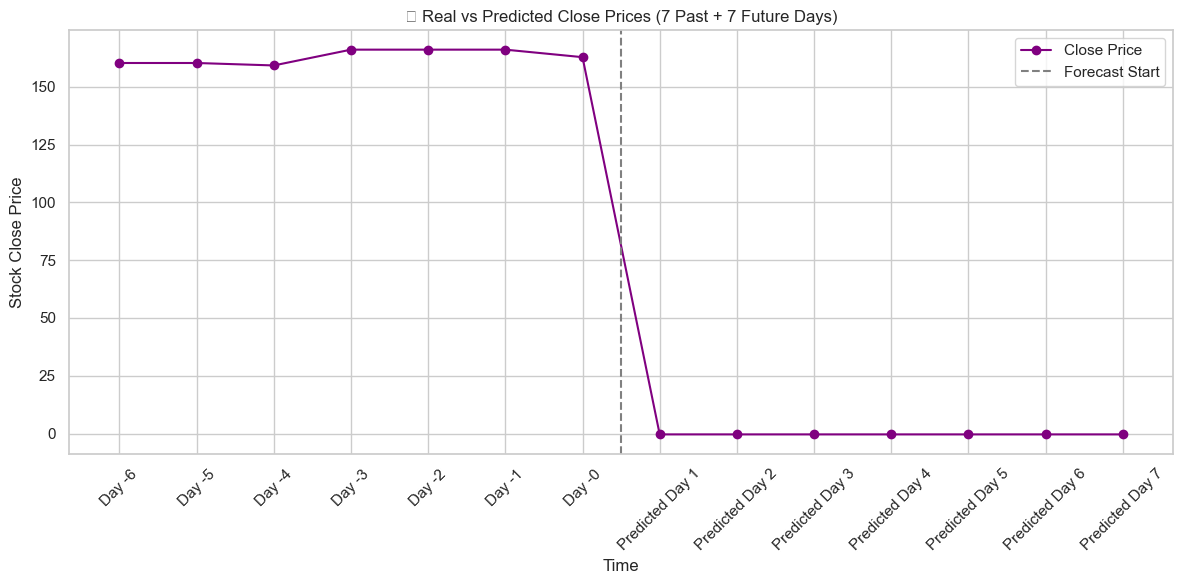

In [746]:


# Get last 7 real close prices (adjust to 7 or more if you like)
real_previous_7 = ba_stock['Close'][-7:].values  

# Combine both
full_series = np.concatenate((real_previous_7, predicted_close.flatten()))

# Build matching labels (7 actual + 7 predicted = 14)
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(days, full_series, marker='o', linestyle='-', color='purple', label='Close Price')
plt.axvline(x=6.5, color='gray', linestyle='--', label='Forecast Start')
plt.title('🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)')
plt.xlabel('Time')
plt.ylabel('Stock Close Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# LSTM FOR  AAPL 

In [747]:
aapl_stock

,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-03,29.534000,AAPL,neutral,0.0000
2020-01-03,29.534000,AAPL,positive,0.1027
2020-01-03,29.534000,AAPL,negative,-0.0516
2020-01-03,29.534000,AAPL,neutral,0.0000
2020-01-03,29.534000,AAPL,neutral,0.0000
...,...,...,...,...
2020-12-29,166.100006,AAPL,neutral,0.0000
2020-12-30,164.292496,AAPL,neutral,0.0000
2020-12-31,162.846497,AAPL,positive,0.0772


In [748]:
# scale
scaler = MinMaxScaler()
aapl_stock['Close_scaled'] = scaler.fit_transform(aapl_stock[['Close']])
aapl_stock['Compound_scaled'] = scaler.fit_transform(aapl_stock[['compound']])


In [749]:
# set x
x=aapl_stock["Compound_scaled"].values

In [750]:
# set for y
y=aapl_stock["Close_scaled"].values


In [751]:
# test and train size
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=0)


In [752]:
# Reshape input for LSTM: (samples, timesteps, features)

x_train = x_train.reshape((x_train.shape[0], 1, 1))
x_test = x_test.reshape((x_test.shape[0], 1, 1))


In [776]:
# Build LSTM model
model = Sequential()
model.add(LSTM(80, activation='relu', input_shape=(x_train.shape[1], 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')


In [777]:
# Train model
model.fit(x_train, y_train, epochs=40, batch_size=16, validation_data=(x_test, y_test))


Epoch 1/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0563 - val_loss: 0.0227
Epoch 2/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0231 - val_loss: 0.0221
Epoch 3/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0221 - val_loss: 0.0217
Epoch 4/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0214 - val_loss: 0.0218
Epoch 5/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0226 - val_loss: 0.0216
Epoch 6/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0214 - val_loss: 0.0217
Epoch 7/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0213 - val_loss: 0.0218
Epoch 8/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0225 - val_loss: 0.0216
Epoch 9/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0215 - val_loss: 0.0217
Epoch 10/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0210 - val_loss: 0.0217
Epoch 11/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0218 - val_loss: 0.0217
Epoch 12/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [784]:
# Make sure last_seq is 2D: (sequence_length, 1)
last_seq = last_seq.reshape(-1, 1)


In [785]:
# Ensure last_seq is shaped correctly
last_seq = last_seq.reshape(-1, 1)
predictions_scaled = []

for _ in range(7):
    next_pred = model.predict(last_seq.reshape(1, -1, 1), verbose=0)[0][0]
    predictions_scaled.append(next_pred)
    last_seq = np.append(last_seq[1:], [[next_pred]], axis=0)

# Inverse scale
predicted_close = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))

# Print results
print("\n📈 Predicted Close Prices:")
print(f"Day 1 ahead: {predicted_close[0][0]:.2f}")
print(f"Day 3 ahead: {predicted_close[2][0]:.2f}")
print(f"Day 7 ahead: {predicted_close[6][0]:.2f}")



📈 Predicted Close Prices:
Day 1 ahead: -0.31
Day 3 ahead: -0.31
Day 7 ahead: -0.31


In [786]:

true_values = aapl_stock['Close'].values[-7:]  

# Reshape
true_values = true_values.reshape(-1, 1)

# compute R²
r2 = r2_score(true_values, predicted_close)
print(f"R² Score: {r2:.4f}")


R² Score: -14888.2447


C:\Users\elias\AppData\Local\Temp\ipykernel_61824\224387294.py:23: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.
  plt.tight_layout()
C:\Users\elias\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


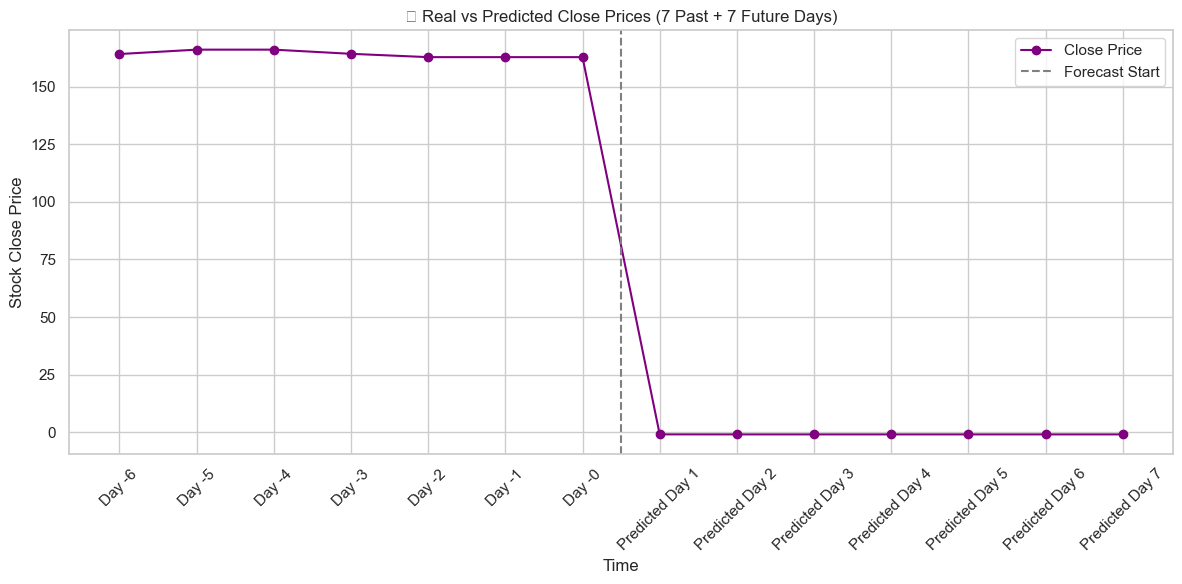

In [602]:


# Get last 7 real close prices (adjust to 7 or more if you like)
real_previous_7 = aapl_stock['Close'][-7:].values  

# Combine both
full_series = np.concatenate((real_previous_7, predicted_close.flatten()))

# Building matching labels (7 actual + 7 predicted = 14)
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(days, full_series, marker='o', linestyle='-', color='purple', label='Close Price')
plt.axvline(x=6.5, color='gray', linestyle='--', label='Forecast Start')
plt.title('🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)')
plt.xlabel('Time')
plt.ylabel('Stock Close Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# LSTM FOR AMZN 

In [189]:
amzn_stock.csv


In [603]:

# scale
scaler = MinMaxScaler()
amzn_stock['Close_scaled'] = scaler.fit_transform(amzn_stock[['Close']])
amzn_stock['Compound_scaled'] = scaler.fit_transform(amzn_stock[['compound']])


In [604]:
# set x
x=amzn_stock["Compound_scaled"].values

In [605]:
# set for y
y=amzn_stock["Close_scaled"].values



In [606]:
# test and train size
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=0)


In [607]:
# Reshape input for LSTM: (samples, timesteps, features)

x_train = x_train.reshape((x_train.shape[0], 1, 1))
x_test = x_test.reshape((x_test.shape[0], 1, 1))


In [764]:
# Build LSTM model
model = Sequential()
model.add(LSTM(25, activation='relu', input_shape=(x_train.shape[1], 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')


C:\Users\elias\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [783]:
# Train model
model.fit(x_train, y_train, epochs=40, batch_size=16, validation_data=(x_test, y_test))


Epoch 1/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0216 - val_loss: 0.0219
Epoch 2/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0218 - val_loss: 0.0217
Epoch 3/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0225 - val_loss: 0.0216
Epoch 4/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0219 - val_loss: 0.0216
Epoch 5/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0215 - val_loss: 0.0217
Epoch 6/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0210 - val_loss: 0.0216
Epoch 7/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0221 - val_loss: 0.0219
Epoch 8/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0227 - val_loss: 0.0217
Epoch 9/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0221 - val_loss: 0.0218
Epoch 10/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0223 - val_loss: 0.0217
Epoch 11/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0213 - val_loss: 0.0217
Epoch 12/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [765]:
# Make sure last_seq is 2D: (sequence_length, 1)
last_seq = last_seq.reshape(-1, 1)


In [766]:
# Ensure last_seq is shaped correctly
last_seq = last_seq.reshape(-1, 1)
predictions_scaled = []

for _ in range(7):
    next_pred = model.predict(last_seq.reshape(1, -1, 1), verbose=0)[0][0]
    predictions_scaled.append(next_pred)
    last_seq = np.append(last_seq[1:], [[next_pred]], axis=0)

# Inverse scale
predicted_close = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))

# Print results
print("\n📈 Predicted Close Prices:")
print(f"Day 1 ahead: {predicted_close[0][0]:.2f}")
print(f"Day 3 ahead: {predicted_close[2][0]:.2f}")
print(f"Day 7 ahead: {predicted_close[6][0]:.2f}")



📈 Predicted Close Prices:
Day 1 ahead: -0.93
Day 3 ahead: -0.93
Day 7 ahead: -0.93


In [767]:

true_values = amzn_stock['Close'].values[-7:]  

# Reshape 
true_values = true_values.reshape(-1, 1)

#  compute R²
r2 = r2_score(true_values, predicted_close)
print(f"R² Score: {r2:.4f}")


R² Score: -4052.2074


C:\Users\elias\AppData\Local\Temp\ipykernel_61824\1680555694.py:23: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.

C:\Users\elias\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.



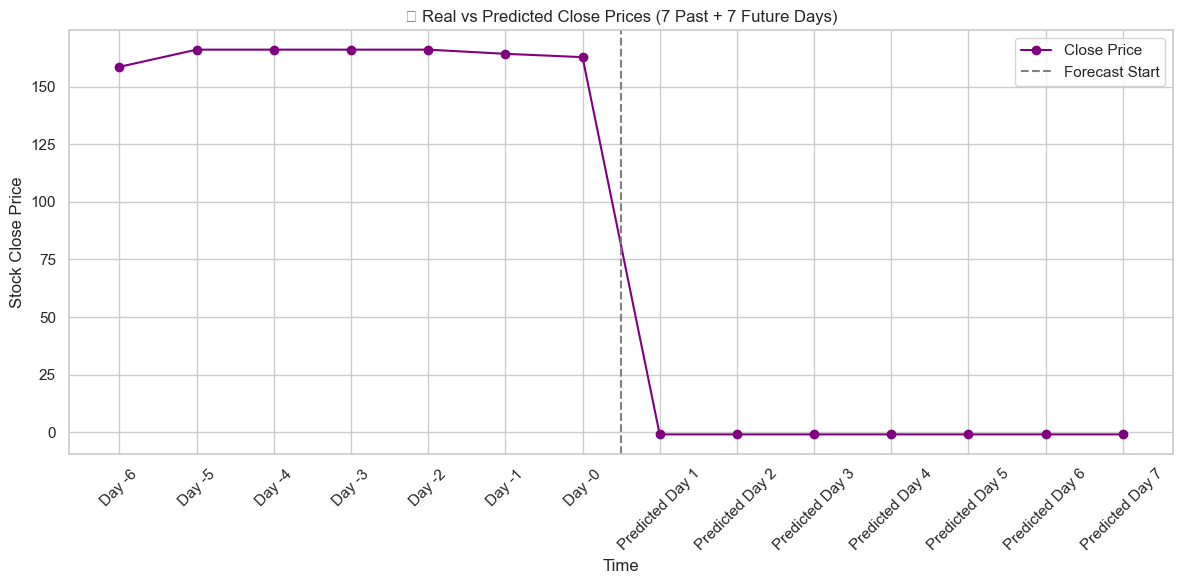

In [768]:

# Get last 7 real close prices (adjust to 7 or more if you like)
real_previous_7 = amzn_stock['Close'][-7:].values  

# Combine both
full_series = np.concatenate((real_previous_7, predicted_close.flatten()))

# Build matching labels (7 actual + 7 predicted = 14)
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(days, full_series, marker='o', linestyle='-', color='purple', label='Close Price')
plt.axvline(x=6.5, color='gray', linestyle='--', label='Forecast Start')
plt.title('🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)')
plt.xlabel('Time')
plt.ylabel('Stock Close Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



# LSTM FOR DIS 

In [613]:
dis_stock


,Close,Ticker,sentiment_label,compound
Date,,,,
2020-01-07,31.270666,DIS,negative,-0.7783
2020-01-08,32.809334,DIS,positive,0.5468
2020-01-08,32.809334,DIS,neutral,0.0000
2020-01-09,32.089333,DIS,positive,0.4939
2020-01-09,32.089333,DIS,neutral,0.0000
...,...,...,...,...
2020-12-30,164.292496,DIS,negative,-0.6597
2020-12-30,164.292496,DIS,neutral,0.0000
2020-12-30,164.292496,DIS,negative,-0.3182


In [614]:
# scale
scaler = MinMaxScaler()
dis_stock['Close_scaled'] = scaler.fit_transform(dis_stock[['Close']])
dis_stock['Compound_scaled'] = scaler.fit_transform(dis_stock[['compound']])


In [615]:
# set x
x=dis_stock["Compound_scaled"].values

In [616]:
# set for y
y=dis_stock["Close_scaled"].values


In [617]:
# test and train size
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=0)


In [618]:
# Reshape input for LSTM: (samples, timesteps, features)

x_train = x_train.reshape((x_train.shape[0], 1, 1))
x_test = x_test.reshape((x_test.shape[0], 1, 1))


In [769]:
# Build LSTM model
model = Sequential()
model.add(LSTM(25, activation='relu', input_shape=(x_train.shape[1], 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')


C:\Users\elias\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [778]:
# Train model
model.fit(x_train, y_train, epochs=40, batch_size=16, validation_data=(x_test, y_test))


Epoch 1/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0220 - val_loss: 0.0218
Epoch 2/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0216 - val_loss: 0.0217
Epoch 3/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0211 - val_loss: 0.0217
Epoch 4/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0212 - val_loss: 0.0217
Epoch 5/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0205 - val_loss: 0.0217
Epoch 6/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0214 - val_loss: 0.0216
Epoch 7/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0218 - val_loss: 0.0219
Epoch 8/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0226 - val_loss: 0.0218
Epoch 9/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0204 - val_loss: 0.0217
Epoch 10/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0206 - val_loss: 0.0217
Epoch 11/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0220 - val_loss: 0.0216
Epoch 12/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [779]:
# Make sure last_seq is 2D: (sequence_length, 1)
last_seq = last_seq.reshape(-1, 1)


In [780]:
# Ensure last_seq is shaped correctly
last_seq = last_seq.reshape(-1, 1)
predictions_scaled = []

for _ in range(7):
    next_pred = model.predict(last_seq.reshape(1, -1, 1), verbose=0)[0][0]
    predictions_scaled.append(next_pred)
    last_seq = np.append(last_seq[1:], [[next_pred]], axis=0)

# Inverse scale
predicted_close = scaler.inverse_transform(np.array(predictions_scaled).reshape(-1, 1))

# Print results
print("\n📈 Predicted Close Prices:")
print(f"Day 1 ahead: {predicted_close[0][0]:.2f}")
print(f"Day 3 ahead: {predicted_close[2][0]:.2f}")
print(f"Day 7 ahead: {predicted_close[6][0]:.2f}")


📈 Predicted Close Prices:
Day 1 ahead: -0.33
Day 3 ahead: -0.32
Day 7 ahead: -0.32


In [782]:

true_values = dis_stock['Close'].values[-7:]  

# Reshape 
true_values = true_values.reshape(-1, 1)

# compute R²
r2 = r2_score(true_values, predicted_close)
print(f"R² Score: {r2:.4f}")


R² Score: -26150.7016


C:\Users\elias\AppData\Local\Temp\ipykernel_61824\3186213328.py:23: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.
  plt.tight_layout()
C:\Users\elias\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


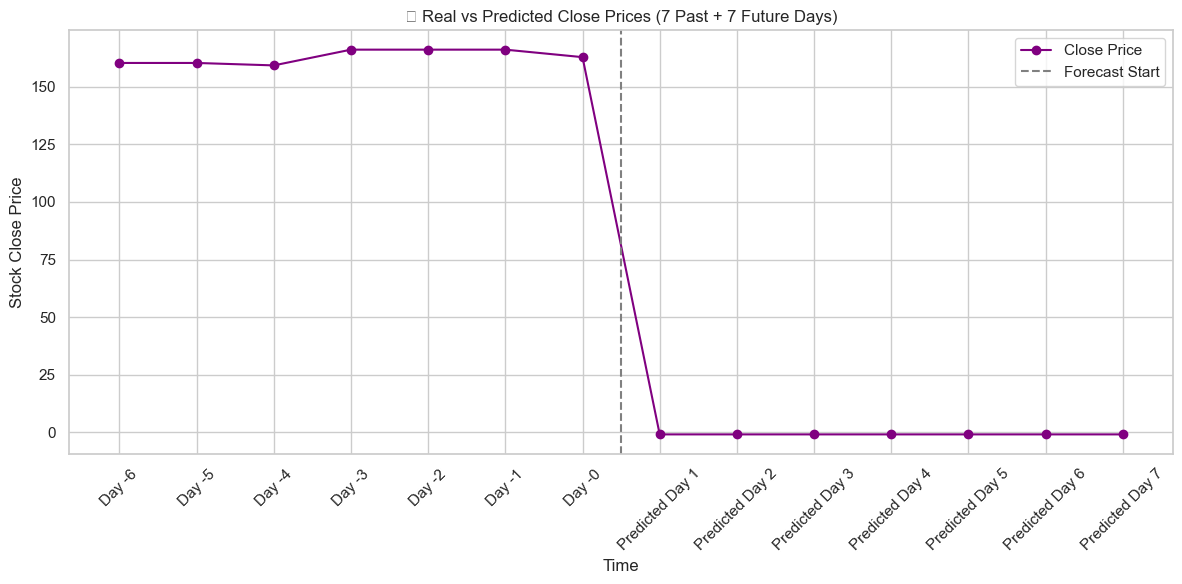

In [623]:

# Get last 7 real close prices (adjust to 7 or more if you like)
real_previous_7 = ba_stock['Close'][-7:].values  

# Combine both
full_series = np.concatenate((real_previous_7, predicted_close.flatten()))

# Build matching labels (7 actual + 7 predicted = 14)
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(days, full_series, marker='o', linestyle='-', color='purple', label='Close Price')
plt.axvline(x=6.5, color='gray', linestyle='--', label='Forecast Start')
plt.title('🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)')
plt.xlabel('Time')
plt.ylabel('Stock Close Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



# Dashboard

In [820]:
import dash
from dash import html, dcc
import plotly.graph_objs as go
import pandas as pd
import numpy as np


In [819]:


# Ensure predicted_close is a 1D array
predicted_close = predicted_close.flatten()

# Get last 7 actual close prices
real_previous_7 = dis_stock['Close'][-7:].values

# Combined real and predicted values
full_series = np.concatenate((real_previous_7, predicted_close))

# Create labels for x-axis
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Initialize Dash app
app = dash.Dash(__name__)
app.title = "DIS Forecast Dashboard"

# Define layout
app.layout = html.Div([
    html.H1("📈 DIS Close Price Forecast Dashboard"),

    dcc.Graph(
        id='forecast-graph',
        figure={
            'data': [
                go.Scatter(x=days, y=full_series, mode='lines+markers', name='Close Price'),
                go.Scatter(
                    x=[days[6], days[6]],
                    y=[min(full_series), max(full_series)],
                    mode='lines',
                    name='Forecast Start',
                    line=dict(dash='dash', color='gray')
                )
            ],
            'layout': go.Layout(
                title='🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)',
                xaxis={'title': 'Time'},
                yaxis={'title': 'Stock Close Price'},
                template='plotly_white'
            )
        }
    )
])

# Run app with fallback port handling
if __name__ == '__main__':
    try:
        app.run_server(debug=True, port=8051)  # Use a different port for DIS
    except OSError as e:
        if "Address" in str(e) and "already in use" in str(e):
            print("⚠️ Port 8051 in use. Trying port 8052...")
            app.run_server(debug=True, port=8052)
        else:
            raise


In [815]:


# Ensure predicted_close is a 1D array
predicted_close = predicted_close.flatten()

# Get last 7 actual close prices
real_previous_7 = amzn_stock['Close'][-7:].values

# Combined real and predicted values
full_series = np.concatenate((real_previous_7, predicted_close))

# Create labels for x-axis
days = [f'Day -{i}' for i in range(6, -1, -1)] + [f'Predicted Day {i+1}' for i in range(7)]

# Initialize Dash app
app = dash.Dash(__name__)
app.title = "DIS Forecast Dashboard"

# Define layout
app.layout = html.Div([
    html.H1("📈 amzn Close Price Forecast Dashboard"),

    dcc.Graph(
        id='forecast-graph',
        figure={
            'data': [
                go.Scatter(x=days, y=full_series, mode='lines+markers', name='Close Price'),
                go.Scatter(
                    x=[days[6], days[6]],
                    y=[min(full_series), max(full_series)],
                    mode='lines',
                    name='Forecast Start',
                    line=dict(dash='dash', color='gray')
                )
            ],
            'layout': go.Layout(
                title='🔮 Real vs Predicted Close Prices (7 Past + 7 Future Days)',
                xaxis={'title': 'Time'},
                yaxis={'title': 'Stock Close Price'},
                template='plotly_white'
            )
        }
    )
])

# Run app with fallback port handling
if __name__ == '__main__':
    try:
        app.run_server(debug=True, port=8052)  # Use a different port for DIS
    except OSError as e:
        if "Address" in str(e) and "already in use" in str(e):
            print("⚠️ Port 8051 in use. Trying port 8052...")
            app.run_server(debug=True, port=8052)
        else:
            raise
